# 04 · Value uplift on existing homes

1. **Hedonic model.** Across ~21k sales in SE16, SE8, E14 and E1W, regress
   log price on log travel time to Canary Wharf, controlling for property type,
   new build, tenure, year of sale, distance to the river and (in some
   specifications) postcode district. The coefficient on log time is the
   **elasticity**: the % change in price per 1% change in access time.
2. **Apply** the elasticity to the before→after time change for every Census
   output area (OA), times its number of households, times local house prices.

This gives the uplift on **existing homes only**. It leaves out new development
that the tunnel makes viable (the bigger prize for land readjustment) and
commercial property.

**Main weaknesses**

- The comparison is cross-sectional: places closer to Canary Wharf may differ
  in ways the controls miss (build quality, views, schools).
- Price Paid has no floor area, so size differences go into the error term.
  Joining EPC floor areas is the obvious next step.
- Household counts come from Census 2021 (occupied homes only), and each OA is
  valued at the median local sale price, including council and housing
  association homes that rarely sell.


In [ ]:
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from common import BNG, DERIVED, FIGURES, RAW, attach_access, ons_layer

## Hedonic regressions


In [ ]:
river = gpd.read_file(RAW / "thames.gpkg").to_crs(BNG).union_all()
sales = gpd.read_file(DERIVED / "sales.gpkg").to_crs(BNG)
sales["river_m"] = sales.distance(river)
sales["log_price"] = np.log(sales.price)
sales["log_access"] = np.log(sales.access_before)
# "Multimodal" access treats cycling as available to everyone: min(walk/PT, cycle)
sales["log_multimodal"] = np.log(np.minimum(sales.access_before, sales.cycle_before))
sales["log_river"] = np.log(sales.river_m)

CONTROLS = "C(property_type) + C(new_build) + C(estate_type) + C(year) + log_river"
SPECS = {
    "A: access": "log_access",
    "B: access + district FE": "log_access + C(district)",
    "C: multimodal + district FE": "log_multimodal + C(district)",
}
models = {
    name: smf.ols(f"log_price ~ {rhs} + {CONTROLS}", sales).fit(
        cov_type="cluster", cov_kwds={"groups": sales.postcode}
    )
    for name, rhs in SPECS.items()
}

pd.DataFrame(
    {
        name: {
            "elasticity: access time": m.params.get("log_access", m.params.get("log_multimodal")),
            "  (s.e.)": m.bse.get("log_access", m.bse.get("log_multimodal")),
            "elasticity: river distance": m.params.get("log_river"),
            "R²": m.rsquared,
            "n": int(m.nobs),
        }
        for name, m in models.items()
    }
).round(3)

,A: access,B: access + district FE,C: multimodal + district FE
elasticity: access time,-0.187,-0.310,-0.261
(s.e.),0.027,0.028,0.032
elasticity: river distance,-0.157,-0.129,-0.108
R²,0.266,0.328,0.322
n,20926.000,20926.000,20926.000


## Housing stock by output area


In [ ]:
oa = ons_layer("OA_December_2021_EW_PWC_V4")
with zipfile.ZipFile(RAW / "ts044.zip") as z, z.open("census2021-ts044-oa.csv") as f:
    hh = pd.read_csv(f, usecols=["geography code", "Accommodation type: Total: All households"])
hh.columns = ["OA21CD", "households"]
oa = oa.merge(hh, on="OA21CD")
oa = attach_access(oa)

msoa = ons_layer("Middle_layer_Super_Output_Areas_December_2021_Boundaries_EW_BGC_V3")
oa = gpd.sjoin(oa, msoa[["MSOA21NM", "geometry"]].to_crs(BNG), predicate="within").drop(columns="index_right")
oa["borough"] = oa["MSOA21NM"].str.rsplit(" ", n=1).str[0]

# Local value: median price of 2022+ sales within 500 m of the OA centroid
recent = sales[sales.year >= 2022][["price", "geometry"]]
near = gpd.sjoin(
    oa[["OA21CD", "geometry"]].assign(geometry=oa.buffer(500)),
    recent,
    predicate="contains",
)
oa["median_price"] = oa["OA21CD"].map(near.groupby("OA21CD").price.median())
covered = oa["median_price"].notna()
print(f"{covered.sum()} of {len(oa)} OAs have nearby 2022+ sales; the rest (outside the sales districts) are dropped")
oa = oa[covered].copy()
oa["stock_value"] = oa.households * oa.median_price
print(f"Stock: {oa.households.sum():,.0f} households worth ~£{oa.stock_value.sum() / 1e9:.1f}bn")

980 of 1439 OAs have nearby 2022+ sales; the rest (outside the sales districts) are dropped
Stock: 130,970 households worth ~£65.1bn


## Uplift scenarios

| Scenario | Uses                                                          |
| -------- | ------------------------------------------------------------- |
| Low      | spec A elasticity, walk/PT time only                          |
| Central  | spec B elasticity, walk/PT time only                          |
| High     | spec C elasticity, multimodal time (cycling open to everyone) |


In [ ]:
def uplift_pct(df, b, multimodal=False):
    if multimodal:
        before = np.minimum(df.access_before, df.cycle_before)
        after = np.minimum(df.access_after, df.cycle_after)
    else:
        before, after = df.access_before, df.access_after
    return (after / before) ** b - 1


scen = {
    "Low": uplift_pct(oa, models["A: access"].params["log_access"]),
    "Central": uplift_pct(oa, models["B: access + district FE"].params["log_access"]),
    "High": uplift_pct(
        oa,
        models["C: multimodal + district FE"].params["log_multimodal"],
        multimodal=True,
    ),
}
for name, pct in scen.items():
    oa[f"uplift_pct_{name}"] = pct
    oa[f"uplift_gbp_{name}"] = pct * oa.stock_value

summary = pd.DataFrame(
    {
        name: {
            "total uplift (£m)": oa[f"uplift_gbp_{name}"].sum() / 1e6,
            **{f"  of which {b} (£m)": v / 1e6 for b, v in oa.groupby("borough")[f"uplift_gbp_{name}"].sum().items()},
            "households with ≥1% uplift": int(oa.loc[oa[f"uplift_pct_{name}"] >= 0.01, "households"].sum()),
            "max OA uplift (%)": 100 * oa[f"uplift_pct_{name}"].max(),
        }
        for name in scen
    }
).round(1)
summary

,Low,Central,High
total uplift (£m),45.3,76.0,1441.7
of which City of London (£m),0.0,0.0,0.0
of which Greenwich (£m),0.0,0.0,27.4
of which Lewisham (£m),0.0,0.0,470.0
of which Newham (£m),0.0,0.0,0.0
of which Southwark (£m),45.3,76.0,944.3
of which Tower Hamlets (£m),0.0,0.0,0.0
households with ≥1% uplift,2481.0,2481.0,30855.0
max OA uplift (%),9.2,15.6,38.9


## Against tunnel cost

**The cost figures below are placeholders** until the cost notebook is done.
The table shows what share of the uplift on existing homes would have to be
captured to pay for a tunnel at each cost.


In [ ]:
ILLUSTRATIVE_COSTS_M = [100, 250, 500]
pd.DataFrame(
    {
        f"£{c}m tunnel": {name: f"{c / summary.loc['total uplift (£m)', name]:.0%}" for name in scen}
        for c in ILLUSTRATIVE_COSTS_M
    }
)

,£100m tunnel,£250m tunnel,£500m tunnel
Low,221%,552%,1104%
Central,132%,329%,658%
High,7%,17%,35%


## Map


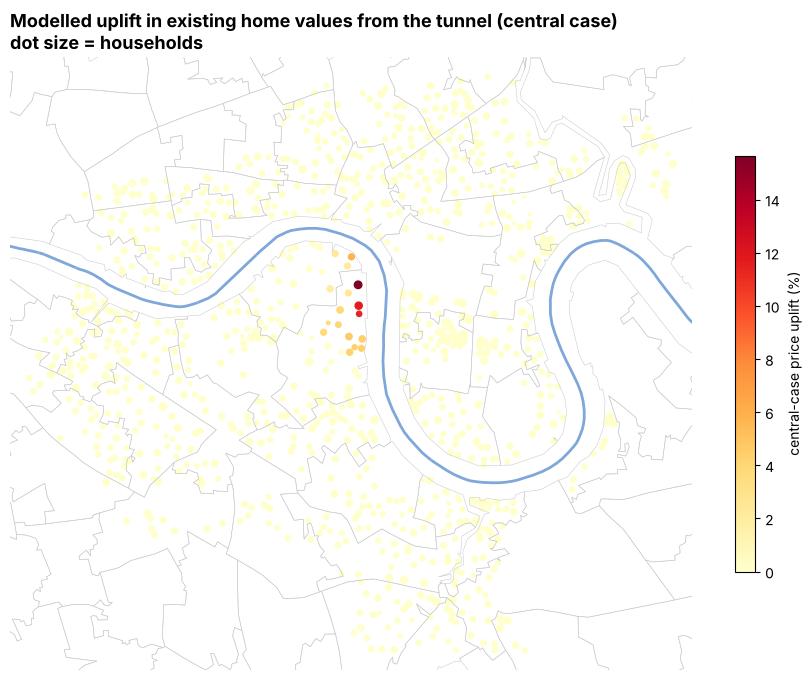

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
oa.plot(
    ax=ax,
    column=100 * oa["uplift_pct_Central"],
    cmap="YlOrRd",
    markersize=oa.households / 8,
    legend=True,
    vmin=0,
    legend_kwds={"label": "central-case price uplift (%)", "shrink": 0.6},
)
msoa.to_crs(BNG).boundary.plot(ax=ax, color="#ccc", linewidth=0.4)
gpd.read_file(RAW / "thames.gpkg").to_crs(BNG).plot(ax=ax, color="#7fa7d9", linewidth=2)
xmin, ymin, xmax, ymax = oa.total_bounds
ax.set_xlim(xmin - 200, xmax + 200)
ax.set_ylim(ymin - 200, ymax + 200)
ax.set_axis_off()
ax.set_title(
    "Modelled uplift in existing home values from the tunnel (central case)\ndot size = households",
    fontsize=13,
    fontweight="bold",
    loc="left",
)
fig.savefig(FIGURES / "04_uplift_map.png", dpi=150, bbox_inches="tight")

In [7]:
oa.drop(columns="geometry").to_csv(DERIVED / "oa_uplift.csv", index=False)